In [17]:

import pandas as pd

df = pd.read_csv("/content/online_shoppers_intention.csv")

print("Dataset carregado!")
print("Dimensões:", df.shape)

display(df.head())


Dataset carregado!
Dimensões: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [18]:
# Informações gerais do dataset
print("Tipos de dados:")
display(df.dtypes)

print("\nValores ausentes por coluna:")
display(df.isnull().sum())

print("\nResumo estatístico:")
display(df.describe())

Tipos de dados:


,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Valores ausentes por coluna:


,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Resumo estatístico:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [19]:
print("Distribuição de Month:")
display(df["Month"].value_counts())

print("\nDistribuição de VisitorType:")
display(df["VisitorType"].value_counts())

print("\nDistribuição de Weekend:")
display(df["Weekend"].value_counts())

print("\nDistribuição de Revenue:")
display(df["Revenue"].value_counts())

Distribuição de Month:


,count
Month,
May,3364
Nov,2998
Mar,1907
Dec,1727
Oct,549
Sep,448
Aug,433
Jul,432
June,288



Distribuição de VisitorType:


,count
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85



Distribuição de Weekend:


,count
Weekend,
False,9462
True,2868



Distribuição de Revenue:


,count
Revenue,
False,10422
True,1908


In [20]:

# Criando uma cópia dos dados, sem a coluna Revenue
X = df.drop(columns=["Revenue"]).copy()

# Convertendo Weekend de booleano para inteiro (0 e 1)
X["Weekend"] = X["Weekend"].astype(int)

# Convertendo as variáveis categóricas em colunas numéricas
colunas_categoricas = [
    "Month",
    "VisitorType",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

X = pd.get_dummies(
    X,
    columns=colunas_categoricas,
    dtype=int
)

# Conferindo a matriz final
print("Matriz X criada!")
print("Dimensões:", X.shape)

display(X.head())


Matriz X criada!
Dimensões: (12330, 74)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType_11,TrafficType_12,TrafficType_13,TrafficType_14,TrafficType_15,TrafficType_16,TrafficType_17,TrafficType_18,TrafficType_19,TrafficType_20
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [21]:

from sklearn.preprocessing import StandardScaler

# Criando o padronizador
scaler = StandardScaler()

# Aplicando a padronização
X_scaled = scaler.fit_transform(X)

print("Padronização concluída!")
print("Dimensões da matriz padronizada:", X_scaled.shape)

# Conferindo média e desvio padrão de algumas colunas
print("\nMédias das primeiras 5 colunas:")
print(X_scaled.mean(axis=0)[:5])

print("\nDesvios padrão das primeiras 5 colunas:")
print(X_scaled.std(axis=0)[:5])


Padronização concluída!
Dimensões da matriz padronizada: (12330, 74)

Médias das primeiras 5 colunas:
[-2.76610311e-17  5.99322340e-17 -2.30508592e-17 -1.61356015e-17
  4.61017185e-17]

Desvios padrão das primeiras 5 colunas:
[1. 1. 1. 1. 1.]


K = 1 | J = 912420.00
K = 2 | J = 882332.65
K = 3 | J = 856748.45
K = 4 | J = 837223.60
K = 5 | J = 802280.55
K = 6 | J = 795657.50
K = 7 | J = 774249.39
K = 8 | J = 769927.34
K = 9 | J = 743909.75
K = 10 | J = 725383.08


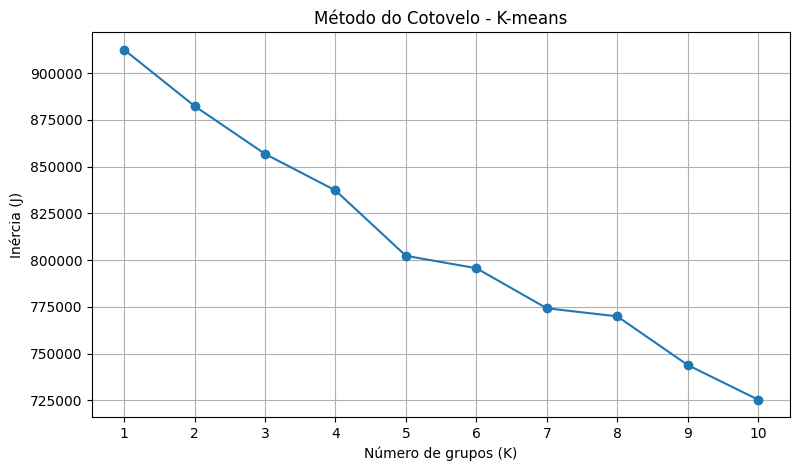

In [22]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Testando K de 1 até 10
valores_k = range(1, 11)
inercia = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    modelo.fit(X_scaled)
    inercia.append(modelo.inertia_)

    print(f"K = {k} | J = {modelo.inertia_:.2f}")

# Gráfico do método do cotovelo
plt.figure(figsize=(9, 5))
plt.plot(valores_k, inercia, marker="o")
plt.title("Método do Cotovelo - K-means")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inércia (J)")
plt.xticks(valores_k)
plt.grid(True)
plt.show()


K = 2 | Silhouette = 0.0683
K = 3 | Silhouette = 0.0776
K = 4 | Silhouette = 0.0458
K = 5 | Silhouette = 0.0734
K = 6 | Silhouette = 0.0364
K = 7 | Silhouette = 0.0596
K = 8 | Silhouette = 0.0705
K = 9 | Silhouette = 0.0709
K = 10 | Silhouette = 0.0602


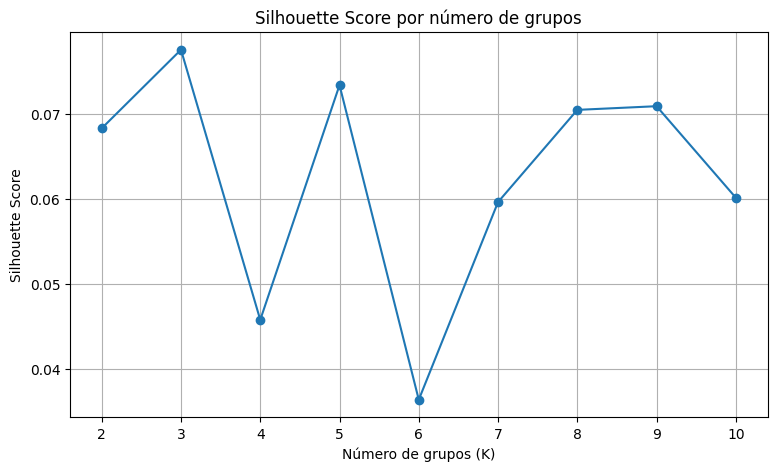

In [23]:

from sklearn.metrics import silhouette_score

# Testando K de 2 até 10
valores_k_silhouette = range(2, 11)
silhouettes = []

for k in valores_k_silhouette:
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = modelo.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouettes.append(score)

    print(f"K = {k} | Silhouette = {score:.4f}")

# Gráfico do Silhouette Score
plt.figure(figsize=(9, 5))
plt.plot(valores_k_silhouette, silhouettes, marker="o")
plt.title("Silhouette Score por número de grupos")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(valores_k_silhouette))
plt.grid(True)
plt.show()


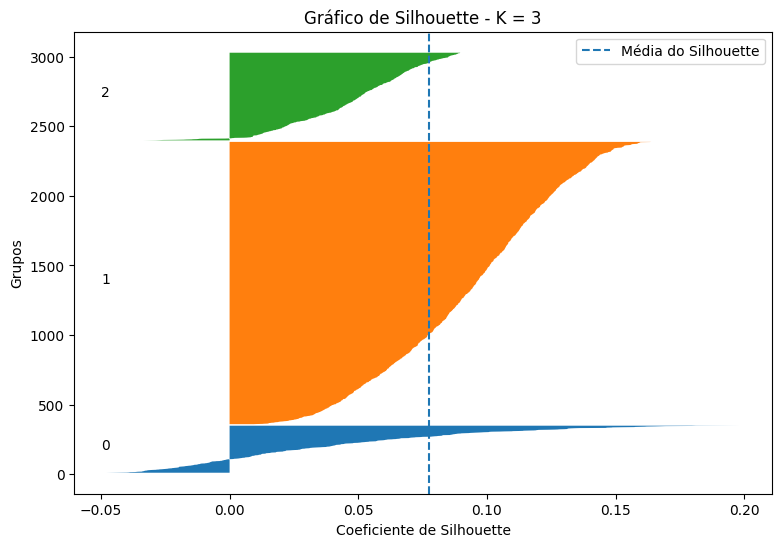

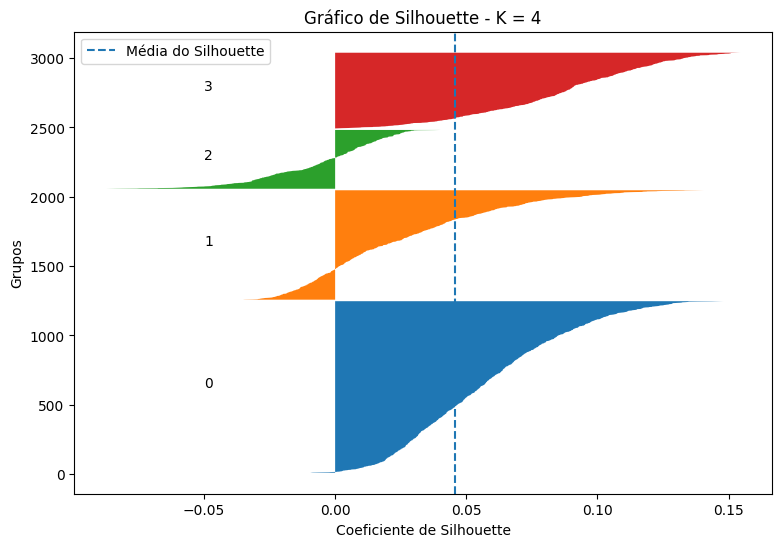

In [24]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples
from sklearn.cluster import KMeans

# Comparando K = 3 e K = 4
for k in [3, 4]:

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = modelo.fit_predict(X_scaled)

    # Usando uma amostra para facilitar a visualização
    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_scaled), size=3000, replace=False)

    X_amostra = X_scaled[indices]
    labels_amostra = labels[indices]

    valores_silhouette = silhouette_samples(
        X_amostra,
        labels_amostra
    )

    plt.figure(figsize=(9, 6))

    y_inferior = 10

    for i in range(k):
        valores_grupo = valores_silhouette[labels_amostra == i]
        valores_grupo.sort()

        tamanho = len(valores_grupo)
        y_superior = y_inferior + tamanho

        plt.fill_betweenx(
            np.arange(y_inferior, y_superior),
            0,
            valores_grupo
        )

        plt.text(-0.05, y_inferior + tamanho / 2, str(i))
        y_inferior = y_superior + 10

    plt.axvline(
        np.mean(valores_silhouette),
        linestyle="--",
        label="Média do Silhouette"
    )

    plt.title(f"Gráfico de Silhouette - K = {k}")
    plt.xlabel("Coeficiente de Silhouette")
    plt.ylabel("Grupos")
    plt.legend()
    plt.show()


In [25]:

# Treinando o modelo definitivo com K = 3
modelo_final = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Atribuindo um grupo para cada sessão
clusters = modelo_final.fit_predict(X_scaled)

# Criando uma cópia dos dados originais com os grupos
df_resultado = df.copy()
df_resultado["Cluster"] = clusters

# Quantidade de registros em cada grupo
print("Quantidade de sessões por grupo:")
display(df_resultado["Cluster"].value_counts().sort_index())

# Percentual de cada grupo
print("\nPercentual de sessões por grupo:")
display(
    (df_resultado["Cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


Quantidade de sessões por grupo:


,count
Cluster,
0,1433
1,8305
2,2592



Percentual de sessões por grupo:


,proportion
Cluster,
0,11.62
1,67.36
2,21.02


## 3. Avaliação crítica dos resultados

Apesar de o K-means ter identificado três grupos de sessões, os resultados apresentam algumas limitações.

**1. Baixa separação entre os clusters:** o maior valor médio de Silhouette foi 0,0776, indicando que os grupos possuem sobreposição e não apresentam uma separação muito bem definida.

**2. Diferença no tamanho dos grupos:** os clusters possuem tamanhos desiguais. O Cluster 1 concentra aproximadamente 67,36% das sessões, enquanto o Cluster 0 representa apenas 11,62%.

**3. Limitação da visualização com PCA:** os dois primeiros componentes principais explicam juntos apenas 9,29% da variância dos dados. Portanto, o gráfico em duas dimensões não representa completamente a estrutura dos 74 atributos utilizados.

**4. Características do algoritmo:** o K-means utiliza distâncias para formar os grupos e pode ser influenciado por valores extremos, pela escala das variáveis e pela representação das categorias.

Concluímos que o modelo encontrou padrões de comportamento entre as sessões, mas esses grupos não devem ser interpretados como categorias perfeitamente separadas. Além disso, a associação entre um cluster e a ocorrência de compras não significa que o comportamento identificado seja a causa da compra.

In [26]:

# Variáveis numéricas de comportamento
variaveis_perfil = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Média das variáveis por cluster, nas unidades originais
perfil_clusters = df_resultado.groupby("Cluster")[
    variaveis_perfil
].mean().round(2)

print("Perfil comportamental dos clusters:")
display(perfil_clusters)

# Taxa de conversão de cada cluster
taxa_compra = (
    df_resultado.groupby("Cluster")["Revenue"]
    .mean() * 100
).round(2)

print("\nPercentual de sessões que resultaram em compra:")
display(taxa_compra)


Perfil comportamental dos clusters:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Cluster,,,,,,,,,,
0,7.41,306.63,2.51,219.55,104.42,4151.92,0.01,0.02,9.80,0.03
1,1.58,46.42,0.21,8.51,22.76,829.05,0.02,0.05,5.24,0.07
2,1.86,66.19,0.35,15.32,20.30,731.58,0.03,0.05,5.80,0.05



Percentual de sessões que resultaram em compra:


,Revenue
Cluster,
0,30.08
1,13.33
2,14.27


In [27]:

# Convertendo os centroides padronizados para a escala original
centroides_originais = scaler.inverse_transform(
    modelo_final.cluster_centers_
)

# Criando uma tabela com os centroides
df_centroides = pd.DataFrame(
    centroides_originais,
    columns=X.columns
)

df_centroides.index.name = "Cluster"

print("Centroides nas unidades originais:")
display(df_centroides.round(3))


Centroides nas unidades originais:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType_11,TrafficType_12,TrafficType_13,TrafficType_14,TrafficType_15,TrafficType_16,TrafficType_17,TrafficType_18,TrafficType_19,TrafficType_20
Cluster,,,,,,,,,,,,,,,,,,,,,
0,7.406,306.798,2.509,219.730,104.532,4156.644,0.006,0.019,9.803,0.025,...,0.013,0.0,0.056,0.001,-0.000,-0.0,0.0,0.000,0.001,0.008
1,1.579,46.454,0.207,8.534,22.758,829.037,0.023,0.046,5.243,0.071,...,0.021,0.0,0.079,0.001,0.001,0.0,0.0,0.001,0.001,0.012
2,1.864,66.192,0.346,15.323,20.299,731.579,0.027,0.048,5.801,0.052,...,0.020,0.0,0.001,0.000,0.010,-0.0,0.0,0.000,0.001,0.034


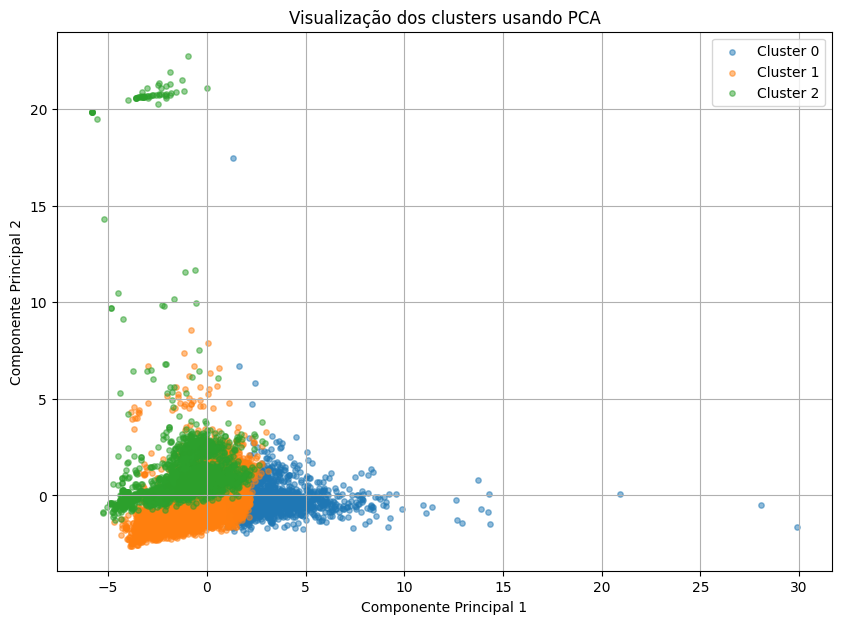

Variância explicada:
Componente 1: 5.00%
Componente 2: 4.29%
Total: 9.29%


In [28]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduzindo os dados para duas dimensões
pca = PCA(n_components=2)

X_2d = pca.fit_transform(X_scaled)

# Criando o gráfico
plt.figure(figsize=(10, 7))

for cluster in range(3):
    plt.scatter(
        X_2d[clusters == cluster, 0],
        X_2d[clusters == cluster, 1],
        label=f"Cluster {cluster}",
        alpha=0.5,
        s=15
    )

plt.title("Visualização dos clusters usando PCA")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.grid(True)
plt.show()

# Percentual da variância explicado pelos componentes
print("Variância explicada:")
print(f"Componente 1: {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"Componente 2: {pca.explained_variance_ratio_[1] * 100:.2f}%")
print(
    f"Total: {sum(pca.explained_variance_ratio_) * 100:.2f}%"
)


In [29]:

# Distribuição percentual de visitantes por cluster
print("Tipo de visitante por cluster (%):")
display(
    pd.crosstab(
        df_resultado["Cluster"],
        df_resultado["VisitorType"],
        normalize="index"
    ).mul(100).round(2)
)

# Distribuição percentual de compras por cluster
print("\nCompras por cluster (%):")
display(
    pd.crosstab(
        df_resultado["Cluster"],
        df_resultado["Revenue"],
        normalize="index"
    ).mul(100).round(2)
)

# Distribuição percentual de sessões no fim de semana
print("\nSessões no fim de semana por cluster (%):")
display(
    pd.crosstab(
        df_resultado["Cluster"],
        df_resultado["Weekend"],
        normalize="index"
    ).mul(100).round(2)
)


Tipo de visitante por cluster (%):


VisitorType,New_Visitor,Other,Returning_Visitor
Cluster,,,
0,3.63,0.14,96.23
1,14.79,0.28,84.94
2,15.97,2.31,81.71



Compras por cluster (%):


Revenue,False,True
Cluster,,
0,69.92,30.08
1,86.67,13.33
2,85.73,14.27



Sessões no fim de semana por cluster (%):


Weekend,False,True
Cluster,,
0,74.32,25.68
1,78.84,21.16
2,71.33,28.67


In [30]:

# Salvando os resultados da clusterização
df_resultado.to_csv(
    "resultado_clusters.csv",
    index=False
)

# Salvando os centroides
df_centroides.to_csv(
    "centroides_clusters.csv"
)

print("Arquivos salvos com sucesso!")


Arquivos salvos com sucesso!


In [31]:

# Comparação antes e depois da padronização

coluna = "ProductRelated_Duration"

print("Antes da padronização:")
display(X[[coluna]].head())

indice = X.columns.get_loc(coluna)

print("\nDepois da padronização:")
print(X_scaled[:5, indice])


Antes da padronização:


,ProductRelated_Duration
0,0.000000
1,64.000000
2,0.000000
3,2.666667
4,627.500000



Depois da padronização:
[-0.62434752 -0.59090256 -0.62434752 -0.62295398 -0.29643012]


## 1. Conhecendo o conjunto de dados

### Origem e descrição

O conjunto de dados utilizado neste trabalho é o **Online Shoppers Purchasing Intention Dataset**, obtido no UCI Machine Learning Repository.

O dataset contém 12.330 registros, nos quais cada linha representa uma sessão de navegação de um visitante em uma loja virtual.

O objetivo da análise é identificar grupos de sessões com comportamentos semelhantes de navegação, utilizando o algoritmo K-means.

### Atributos utilizados

| Atributo | Descrição | Tipo | Unidade / representação |
|---|---|---|---|
| Administrative | Quantidade de páginas administrativas visitadas | Numérico | Quantidade de páginas |
| Administrative_Duration | Tempo gasto em páginas administrativas | Numérico | Segundos |
| Informational | Quantidade de páginas informativas visitadas | Numérico | Quantidade de páginas |
| Informational_Duration | Tempo gasto em páginas informativas | Numérico | Segundos |
| ProductRelated | Quantidade de páginas relacionadas a produtos visitadas | Numérico | Quantidade de páginas |
| ProductRelated_Duration | Tempo gasto em páginas de produtos | Numérico | Segundos |
| BounceRates | Taxa de rejeição das páginas | Numérico | Proporção |
| ExitRates | Taxa de saída das páginas | Numérico | Proporção |
| PageValues | Valor associado às páginas | Numérico | Valor numérico |
| SpecialDay | Indicador de proximidade de uma data especial | Numérico | Escala de 0 a 1 |
| Month | Mês da sessão | Categórico | Nome do mês |
| OperatingSystems | Sistema operacional utilizado | Categórico codificado | Código categórico |
| Browser | Navegador utilizado | Categórico codificado | Código categórico |
| Region | Região do visitante | Categórico codificado | Código categórico |
| TrafficType | Tipo de origem do tráfego | Categórico codificado | Código categórico |
| VisitorType | Tipo de visitante | Categórico | Categoria |
| Weekend | Indica se a sessão ocorreu no fim de semana | Booleano | 0 = Não; 1 = Sim |
| Revenue | Indica se houve compra durante a sessão | Booleano | 0 = Não; 1 = Sim |

### Preparação e dimensão da matriz

O conjunto original possui 18 atributos e 12.330 registros. Não foram encontrados valores ausentes.

A coluna Revenue foi excluída da matriz X porque representa o resultado da sessão e não deve influenciar a formação dos clusters.

As variáveis categóricas foram transformadas utilizando One-Hot Encoding, enquanto Weekend foi convertido para valores binários.

Após a preparação, a matriz final utilizada pelo K-means possui:

- Número de instâncias (n): 12.330
- Número de atributos (d): 74
- Dimensão da matriz X: 12.330 × 74

### Justificativa da escolha do número de clusters

Foram testados valores de K entre 1 e 10 utilizando o método do cotovelo, e valores entre 2 e 10 utilizando o coeficiente de Silhouette.

O método do cotovelo não apresentou um ponto de inflexão perfeitamente definido, mas K = 5 demonstrou uma redução relevante da inércia em relação a K = 4.

Já o coeficiente de Silhouette apresentou seu maior valor em K = 3, com média de 0,0776, seguido por K = 5, com 0,0734.

Apesar da proximidade entre esses resultados, escolhemos K = 3 por apresentar o maior Silhouette médio entre os valores testados. Os gráficos individuais de Silhouette também mostraram uma distribuição relativamente melhor para K = 3 do que para K = 4.

O valor baixo do coeficiente indica que existe sobreposição entre os grupos, portanto a escolha representa a melhor alternativa encontrada entre os valores avaliados, e não uma separação perfeita dos dados.

## Interpretação dos clusters

**Cluster 0 — Visitantes mais engajados:** representa 11,62% das sessões. Apresenta maior quantidade de páginas visitadas, maior tempo de navegação e a maior taxa de conversão, de 30,08%.

**Cluster 1 — Navegação mais moderada:** representa 67,36% das sessões, sendo o maior grupo. Apresenta menor engajamento em comparação ao Cluster 0 e taxa de conversão de 13,33%.

**Cluster 2 — Perfil intermediário:** representa 21,02% das sessões. Possui características próximas às do Cluster 1, com taxa de conversão de 14,27% e uma proporção um pouco maior de visitantes novos.

Esses nomes são interpretações dos padrões encontrados pelo algoritmo, e não categorias definidas previamente no conjunto de dados.

### Funcionamento do algoritmo K-means

O K-means é um algoritmo de aprendizado não supervisionado utilizado para agrupar dados com características semelhantes.

Seu funcionamento acontece em cinco etapas:

1. **Definição de K:** escolhemos a quantidade de grupos que queremos encontrar.
2. **Inicialização dos centroides:** o algoritmo utiliza o método K-means++ para escolher posições iniciais dos centroides.
3. **Atribuição dos pontos:** cada sessão é associada ao centroide mais próximo, utilizando a distância euclidiana.
4. **Atualização dos centroides:** o algoritmo calcula a média dos pontos pertencentes a cada grupo para atualizar seus centroides.
5. **Repetição:** as etapas de atribuição e atualização são repetidas até que os grupos se estabilizem ou o algoritmo atinja o critério de parada.

O objetivo é minimizar J, que representa a soma dos quadrados das distâncias entre cada ponto e o centroide do grupo ao qual pertence.